In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

DRIVE_PATH = Path("/content/drive/MyDrive/DeepfakeDetection")

RAW_DATA_PATH = DRIVE_PATH / "data" / "raw" / "faceforensicspp"
INTERIM_PATH = DRIVE_PATH / "data" / "interim" / "extracted_frames"
PROCESSED_PATH = DRIVE_PATH / "data" / "processed"
MODELS_PATH = DRIVE_PATH / "saved_models"
RESULTS_PATH = DRIVE_PATH / "results"

print("Drive project path:", DRIVE_PATH)
print("Raw dataset path:", RAW_DATA_PATH)

Drive project path: /content/drive/MyDrive/DeepfakeDetection
Raw dataset path: /content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp


In [ ]:
for folder in [
    DRIVE_PATH,
    RAW_DATA_PATH,
    INTERIM_PATH,
    PROCESSED_PATH,
    MODELS_PATH,
    RESULTS_PATH
]:
    print(f"{folder}: {'✓ EXISTS' if folder.exists() else '✗ NOT FOUND'}")


/content/drive/MyDrive/DeepfakeDetection: ✓ EXISTS
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp: ✓ EXISTS
/content/drive/MyDrive/DeepfakeDetection/data/interim/extracted_frames: ✓ EXISTS
/content/drive/MyDrive/DeepfakeDetection/data/processed: ✓ EXISTS
/content/drive/MyDrive/DeepfakeDetection/saved_models: ✓ EXISTS
/content/drive/MyDrive/DeepfakeDetection/results: ✓ EXISTS


In [ ]:
!wget -O /content/faceforensics_download_v4.py \
http://kaldir.vc.in.tum.de/faceforensics_download_v4.py

--2026-08-24 09:04:40--  http://kaldir.vc.in.tum.de/faceforensics_download_v4.py
Resolving kaldir.vc.in.tum.de (kaldir.vc.in.tum.de)... 131.159.98.128
Connecting to kaldir.vc.in.tum.de (kaldir.vc.in.tum.de)|131.159.98.128|:80... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://kaldir.vc.in.tum.de:443/faceforensics_download_v4.py [following]
--2026-08-24 09:04:40--  https://kaldir.vc.in.tum.de/faceforensics_download_v4.py
Connecting to kaldir.vc.in.tum.de (kaldir.vc.in.tum.de)|131.159.98.128|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 10727 (10K) [text/x-python]
Saving to: ‘/content/faceforensics_download_v4.py’

/content/faceforens 100%[===================>]  10.48K  --.-KB/s    in 0.008s  

2026-08-24 09:05:18 (1.23 MB/s) - ‘/content/faceforensics_download_v4.py’ saved [10727/10727]



In [ ]:
!python /content/faceforensics_download_v4.py --help

usage: faceforensics_download_v4.py [-h]
                                    [-d {original_youtube_videos,original_youtube_videos_info,original,DeepFakeDetection_original,Deepfakes,DeepFakeDetection,Face2Face,FaceShifter,FaceSwap,NeuralTextures,all}]
                                    [-c {raw,c23,c40}]
                                    [-t {videos,masks,models}] [-n NUM_VIDEOS]
                                    [--server {EU,EU2,CA}]
                                    output_path

Downloads FaceForensics v2 public data release.

positional arguments:
  output_path           Output directory.

options:
  -h, --help            show this help message and exit
  -d, --dataset {original_youtube_videos,original_youtube_videos_info,original,DeepFakeDetection_original,Deepfakes,DeepFakeDetection,Face2Face,FaceShifter,FaceSwap,NeuralTextures,all}
                        Which dataset to download, either pristine or
                        manipulated data or the downloaded youtube videos

In [ ]:
OUTPUT_PATH = "/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp"

In [ ]:
import os

print(os.path.exists(OUTPUT_PATH))
print(OUTPUT_PATH)

True
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp


In [ ]:
!python /content/faceforensics_download_v4.py \
"$OUTPUT_PATH" \
-d original \
-c c23 \
-t videos \
-n 10 \
--server EU2

By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
Traceback (most recent call last):
  File "/content/faceforensics_download_v4.py", line 261, in <module>
    main(args)
  File "/content/faceforensics_download_v4.py", line 144, in main
    _ = input('')
KeyboardInterrupt
^C


In [ ]:
from pathlib import Path

files = list(Path(OUTPUT_PATH).rglob("*"))

for file in files[:30]:
    print(file)

/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/original_sequences
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/original_sequences/youtube
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/Deepfakes
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/Face2Face
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/FaceSwap
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/Deepfakes/c23
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/Face2Face/c23
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/FaceSwap/c23
/content/drive/MyDrive/DeepfakeDe

In [ ]:
video_files = list(Path(OUTPUT_PATH).rglob("*.mp4"))

print("Number of MP4 videos:", len(video_files))

for video in video_files[:10]:
    print(video)

Number of MP4 videos: 185
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/585_599.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/599_585.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/469_481.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/481_469.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/183_253.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/253_183.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/672_720.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/Neur

In [ ]:
import cv2

sample_video = video_files[0]

cap = cv2.VideoCapture(str(sample_video))

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps if fps > 0 else 0

print("Video:", sample_video.name)
print("FPS:", fps)
print("Total frames:", frame_count)
print("Resolution:", width, "x", height)
print("Duration:", round(duration, 2), "seconds")

cap.release()

Video: 585_599.mp4
FPS: 30.0
Total frames: 359
Resolution: 1280 x 720
Duration: 11.97 seconds


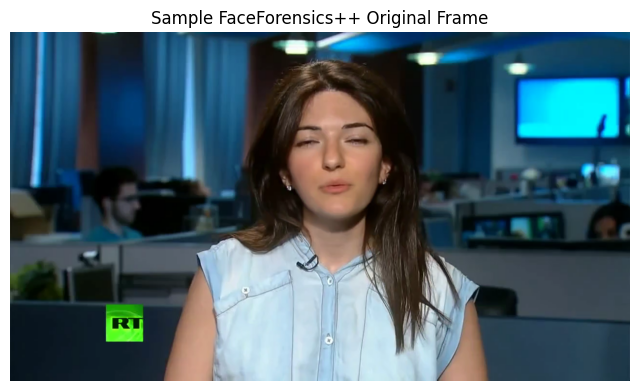

In [ ]:
import cv2
import matplotlib.pyplot as plt

cap = cv2.VideoCapture(str(sample_video))

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
success, frame = cap.read()

cap.release()

if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.title("Sample FaceForensics++ Original Frame")
    plt.show()
else:
    print("Could not read the frame.")

In [ ]:
!python /content/faceforensics_download_v4.py \
"$OUTPUT_PATH" \
-d Deepfakes \
-c c23 \
-t videos \
-n 10 \
--server EU2

By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
Traceback (most recent call last):
  File "/content/faceforensics_download_v4.py", line 261, in <module>
    main(args)
    ~~~~^^^^^^
  File "/content/faceforensics_download_v4.py", line 144, in main
    _ = input('')
KeyboardInterrupt
^C


In [ ]:

from pathlib import Path

all_videos = list(Path(OUTPUT_PATH).rglob("*.mp4"))

print("Total videos:", len(all_videos))

for video in all_videos:
    print(video)

Total videos: 185
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/585_599.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/599_585.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/469_481.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/481_469.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/183_253.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/253_183.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextures/c23/videos/672_720.mp4
/content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/NeuralTextur

In [ ]:
deepfake_videos = [
    p for p in Path(OUTPUT_PATH).rglob("*.mp4")
    if "Deepfakes" in str(p)
]

print("Number of Deepfake videos:", len(deepfake_videos))

for video in deepfake_videos[:10]:
    print(video.name)

Number of Deepfake videos: 10
585_599.mp4
599_585.mp4
469_481.mp4
481_469.mp4
183_253.mp4
253_183.mp4
672_720.mp4
720_672.mp4
866_878.mp4
878_866.mp4


In [ ]:
sample_fake_video = deepfake_videos[0]

cap = cv2.VideoCapture(str(sample_fake_video))

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

duration = frame_count / fps if fps > 0 else 0

print("Video:", sample_fake_video.name)
print("FPS:", fps)
print("Total frames:", frame_count)
print("Resolution:", width, "x", height)
print("Duration:", round(duration, 2), "seconds")

cap.release()

Video: 585_599.mp4
FPS: 30.0
Total frames: 359
Resolution: 1280 x 720
Duration: 11.97 seconds


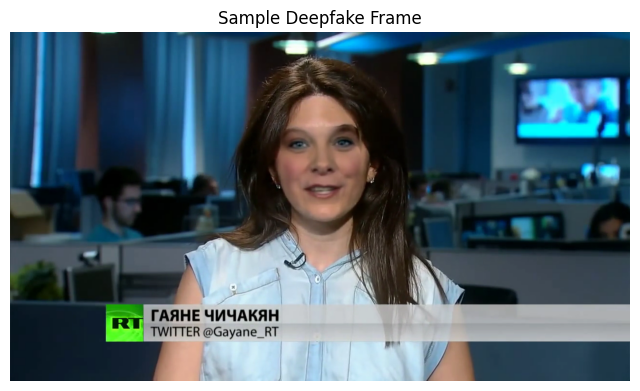

In [ ]:
cap = cv2.VideoCapture(str(sample_fake_video))

middle_frame = frame_count // 2
cap.set(cv2.CAP_PROP_POS_FRAMES, middle_frame)

success, frame = cap.read()
cap.release()

if success:
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(8, 6))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.title("Sample Deepfake Frame")
    plt.show()

In [ ]:
from pathlib import Path

original_videos = [
    p for p in Path(OUTPUT_PATH).rglob("*.mp4")
    if "original_sequences" in str(p)
]

print("Original videos currently downloaded:", len(original_videos))

for video in original_videos[:15]:
    print(video.name)

Original videos currently downloaded: 100
585.mp4
599.mp4
469.mp4
481.mp4
183.mp4
253.mp4
672.mp4
720.mp4
866.mp4
878.mp4
339.mp4
392.mp4
828.mp4
830.mp4
252.mp4


In [ ]:
deepfake_videos = [
    p for p in Path(OUTPUT_PATH).rglob("*.mp4")
    if "Deepfakes" in str(p)
]

print("Deepfake videos currently downloaded:", len(deepfake_videos))

for video in deepfake_videos[:15]:
    print(video.name)

Deepfake videos currently downloaded: 10
585_599.mp4
599_585.mp4
469_481.mp4
481_469.mp4
183_253.mp4
253_183.mp4
672_720.mp4
720_672.mp4
866_878.mp4
878_866.mp4


In [ ]:
!grep -n "num_videos\|skip\|exists" /content/faceforensics_download_v4.py | head -50

69:    parser.add_argument('-n', '--num_videos', type=int, default=None,
134:        tqdm.write('WARNING: skipping download of existing file ' + out_file)
150:    num_videos = args.num_videos
204:        if num_videos is not None and num_videos > 0:
205:        	print('Downloading the first {} videos'.format(num_videos))
206:        	filelist = filelist[:num_videos]


In [ ]:
!python /content/faceforensics_download_v4.py \
"$OUTPUT_PATH" \
-d original \
-c c23 \
-t videos \
-n 100 \
--server EU2

By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
Traceback (most recent call last):
  File "/content/faceforensics_download_v4.py", line 261, in <module>
    main(args)
  File "/content/faceforensics_download_v4.py", line 144, in main
    _ = input('')
KeyboardInterrupt
^C


In [ ]:
!python /content/faceforensics_download_v4.py \
"$OUTPUT_PATH" \
-d Face2Face \
-c c23 \
-t videos \
-n 25 \
--server EU2

By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
g
Output path: /content/drive/MyDrive/DeepfakeDetection/data/raw/faceforensicspp/manipulated_sequences/Face2Face/c23/videos
100% 25/25 [00:00<00:00, 1461.06it/s]


In [ ]:

!python /content/faceforensics_download_v4.py \
"$OUTPUT_PATH" \
-d FaceSwap \
-c c23 \
-t videos \
-n 25 \
--server EU2

By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
Traceback (most recent call last):
Traceback (most recent call last):
  File "/content/faceforensics_download_v4.py", line 261, in <module>
    main(args)
  File "/content/faceforensics_download_v4.py", line 144, in main
    _ = input('')
KeyboardInterrupt
^C


In [ ]:
!python /content/faceforensics_download_v4.py \
"$OUTPUT_PATH" \
-d NeuralTextures \
-c c23 \
-t videos \
-n 25 \
--server EU2

By pressing any key to continue you confirm that you have agreed to the FaceForensics terms of use as described at:
http://kaldir.vc.in.tum.de/faceforensics/webpage/FaceForensics_TOS.pdf
***
Press any key to continue, or CTRL-C to exit.
Traceback (most recent call last):
  File "/content/faceforensics_download_v4.py", line 261, in <module>
    main(args)
  File "/content/faceforensics_download_v4.py", line 144, in main
    _ = input('')
KeyboardInterrupt
^C


In [ ]:
print("Original:", len(original_videos))
print("Deepfakes:", len(deepfake_videos))

Original: 100
Deepfakes: 10
